<a href="https://colab.research.google.com/github/fddxxueyj/SINDy-ENSO-Recharge-Discharge-Model/blob/main/FD_SINDy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
!pip install pysindy

In [8]:
import numpy as np
import scipy
import pysindy
import matplotlib.pyplot as plt

In [9]:
from google.colab import drive
drive.mount('/content/drive')

import sys

sys.path.append('/content/drive/MyDrive/SINDy_ENSO/')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [10]:
from fourier_delay_sindy import FourierDelaySINDy

In [11]:
def simulate_dde(rhs, history, tau, dt, total_time, sigma=0.0, seed=7):
    """Euler / Euler-Maruyama for a fixed-lag DDE and constant history.

    rhs(x_now, x_past) -> array-like drift; sigma is process-noise strength.
    The true tau for *simulation* is a multiple of dt, but the fitted tau
    is continuous and need not be one.
    """
    x0 = np.atleast_1d(np.asarray(history, dtype=float))
    n = int(round(total_time / dt))
    lag_steps = int(round(tau / dt))
    if not np.isclose(lag_steps * dt, tau, rtol=0, atol=1e-9):
        raise ValueError('For this simple simulator, choose tau divisible by dt')
    rng = np.random.default_rng(seed)
    data = np.empty((n + 1, x0.size), dtype=float)
    data[0] = x0
    for k in range(n):
        past = data[k - lag_steps] if k >= lag_steps else x0
        drift = np.asarray(rhs(data[k], past), dtype=float)
        data[k + 1] = (data[k] + dt * drift
                       + sigma * np.sqrt(dt) * rng.normal(size=x0.size))
    t = np.arange(n + 1) * dt
    return t, data[:, 0] if x0.size == 1 else data


def report_model(title, true_tau, t, x, model, names=None):
    print('\n' + '=' * 60)
    print(title)
    print('True delay       :', true_tau)
    print('Estimated delay  :', round(model.delay_, 6))
    print('Absolute error   :', round(abs(model.delay_ - true_tau), 6))
    print('MSE              :', f'{model.mse_:.5e}')
    print('Derivative R²    :', f'{model.score():.5f}')
    model.print()

    xx = np.asarray(x)
    if xx.ndim == 1:
        xx = xx[:, None]
    yy = np.asarray(model.y_)
    pred = np.asarray(model.predict())
    if pred.ndim == 1:
        pred = pred[:, None]
    valid_t = t[model.valid_indices_]

    fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
    stride = max(1, len(t) // 1400)
    for j in range(xx.shape[1]):
        name = (names[j] if names else f'x{j}')
        axes[0].plot(t[::stride], xx[::stride, j], label=name, lw=1)
    axes[0].set_title(title + ': trajectory')
    axes[0].set_xlabel('t')
    axes[0].legend()

    # Show one representative equation's derivative fit.
    sel = max(1, len(valid_t) // 1500)
    axes[1].plot(valid_t[::sel], yy[::sel, 0], label='Derivative target', lw=1)
    axes[1].plot(valid_t[::sel], pred[::sel, 0], '--',
                 label='SINDy drift fit', lw=1)
    axes[1].set_title('Derivative fit (first equation)')
    axes[1].set_xlabel('t')
    axes[1].legend()
    plt.tight_layout()
    plt.show()


In [12]:
results = []

/usr/local/lib/python3.13/dist-packages/pysindy/optimizers/stlsq.py:224: UserWarning: Sparsity parameter is too big (3.760992808962719) and eliminated all coefficients
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/pysindy/optimizers/stlsq.py:224: UserWarning: Sparsity parameter is too big (3.760992808962719) and eliminated all coefficients
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/pysindy/optimizers/stlsq.py:224: UserWarning: Sparsity parameter is too big (3.76099899580412) and eliminated all coefficients
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/pysindy/optimizers/stlsq.py:224: UserWarning: Sparsity parameter is too big (3.76099899580412) and eliminated all coefficients
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/pysindy/optimizers/stlsq.py:224: UserWarning: Sparsity parameter is too big (3.760997717874777) and eliminated all coefficients
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/pysindy/optimizers/stlsq.py:224: User


Mackey-Glass (process noise)
True delay       : 17.0
Estimated delay  : 17.100312
Absolute error   : 0.100312
MSE              : 3.52950e-05
Derivative R²    : 0.96782
Estimated delay: 17.1003
(x)' = (-0.10121)*x + (0.20202)*x_delay/(1+x_delay^10)


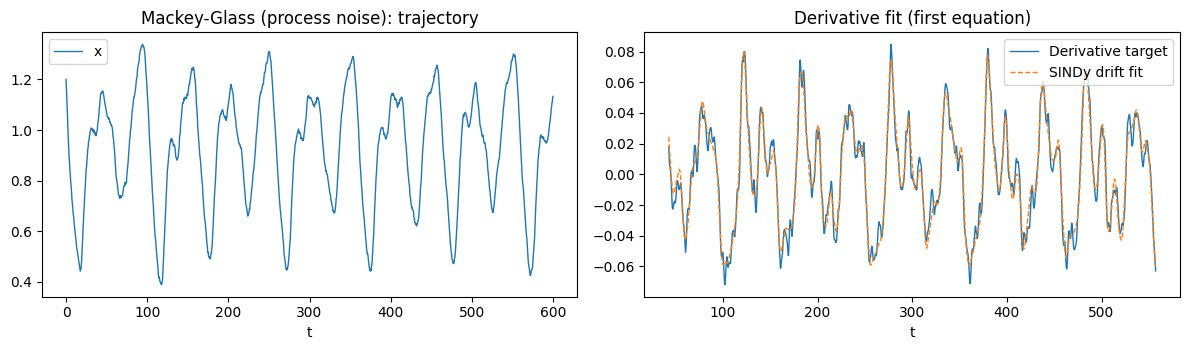

In [13]:
# =============================================================================
# Example 1: Mackey-Glass with ADDITIVE PROCESS NOISE
# dX = [-0.1 X + 0.2 X_tau/(1+X_tau**10)] dt + 0.008 dW
# =============================================================================
dt_mg, true_mg = 0.1, 17.0

def rhs_mg(x, z):
    return -0.1 * x + 0.2 * z / (1 + z**10)

def h_mg(z):
    return z / (1 + z**10)

def dh_mg(z):
    return (1 - 9 * z**10) / (1 + z**10)**2

t_mg, x_mg = simulate_dde(
    rhs_mg, history=[1.2], tau=true_mg, dt=dt_mg,
    total_time=600, sigma=0.008, seed=7
)

model_mg = FourierDelaySINDy(
    degree=3, poly_on='current',
    delay_function=h_mg, delay_derivative=dh_mg,
    delay_feature_name='x_delay/(1+x_delay^10)',
    delay_bounds=(0.1, 40.0), max_delay=40.0,
    cutoff_period=2.0, sg_window=51, sg_order=3,
    threshold=0.2, n_starts=6, n_alternations=2,
    adam_lr=0.08, adam_iters=250, random_state=42,
    selection='bic'
)
model_mg.fit(x_mg, t=dt_mg, feature_names=['x'])
report_model('Mackey-Glass (process noise)', true_mg, t_mg, x_mg,
             model_mg, ['x'])
results.append(('Mackey-Glass', true_mg, model_mg.delay_, model_mg.mse_))




Delayed logistic
True delay       : 1.0
Estimated delay  : 1.019891
Absolute error   : 0.019891
MSE              : 6.16913e-05
Derivative R²    : 0.99996
Estimated delay: 1.01989
(x)' = (1.789)*x + (-1.8177)*x x_delay


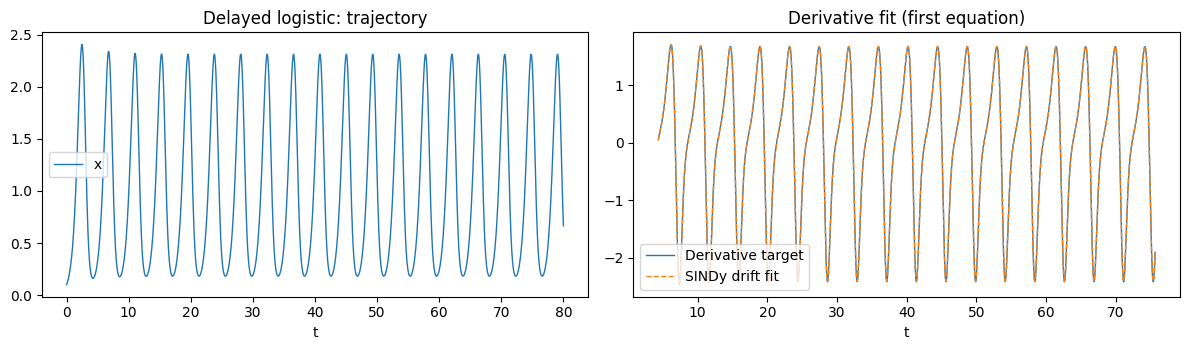

In [14]:
# =============================================================================
# Example 2: Hutchinson delayed logistic equation
# dx/dt = 1.8*x(t)*(1-x(t-1))
# The x*x_delay interaction MUST be automatically selected by SINDy.
# =============================================================================
dt_lg, true_lg, rho = 0.02, 1.0, 1.8

def rhs_lg(x, z):
    return rho * x * (1 - z)

t_lg, x_lg = simulate_dde(
    rhs_lg, history=[0.1], tau=true_lg, dt=dt_lg,
    total_time=80, sigma=0.0
)
model_lg = FourierDelaySINDy(
    degree=2, poly_on='both',
    delay_bounds=(0.2, 4.0), max_delay=4.0,
    cutoff_period=0.18, sg_window=31,
    threshold=0.15, n_starts=6, n_alternations=2,
    adam_lr=0.04, adam_iters=220, random_state=44,
    selection='bic'
)
model_lg.fit(x_lg, t=dt_lg, feature_names=['x'])
report_model('Delayed logistic', true_lg, t_lg, x_lg,
             model_lg, ['x'])
results.append(('Delayed logistic', true_lg, model_lg.delay_, model_lg.mse_))




Delayed cubic oscillator
True delay       : 7.0
Estimated delay  : 7.02951
Absolute error   : 0.02951
MSE              : 4.63457e-04
Derivative R²    : 0.99792
Estimated delay: 7.02951
(x)' = (0.88981)*x + (-0.91871)*x^3 + (-0.72761)*x_delay


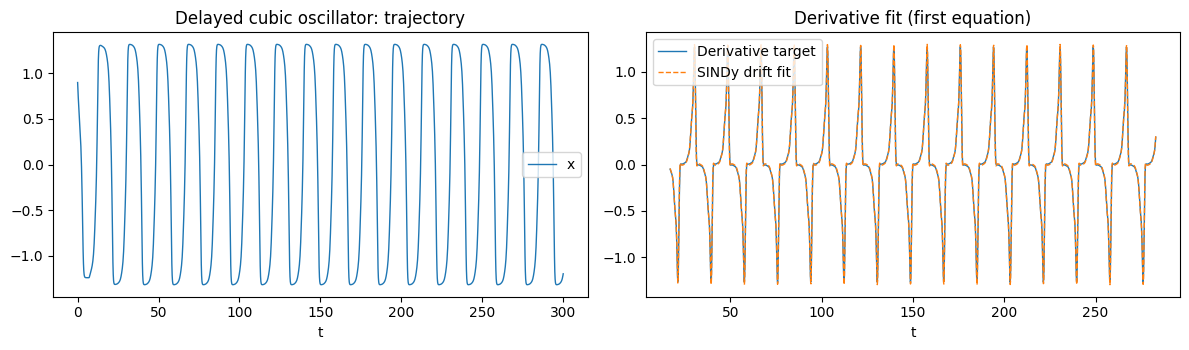

In [15]:
# =============================================================================
# Example 3: Cubic delayed oscillator (ENSO-style toy equation)
# dx/dt = x - x**3 - 0.75*x(t-7)
# IMPORTANT: constant history 0.5 is an exact equilibrium! Use 0.9.
# =============================================================================
dt_os, true_os, alpha = 0.05, 7.0, 0.75

def rhs_os(x, z):
    return x - x**3 - alpha*z

t_os, x_os = simulate_dde(
    rhs_os, history=[0.9], tau=true_os, dt=dt_os,
    total_time=300, sigma=0.0
)
model_os = FourierDelaySINDy(
    degree=3, poly_on='current',
    delay_bounds=(0.5, 16.0), max_delay=16.0,
    cutoff_period=0.5, sg_window=41,
    threshold=0.18, n_starts=7, n_alternations=2,
    adam_lr=0.08, adam_iters=260, random_state=41,
    selection='bic'
)
model_os.fit(x_os, t=dt_os, feature_names=['x'])
report_model('Delayed cubic oscillator', true_os, t_os, x_os,
             model_os, ['x'])
results.append(('Delayed cubic oscillator', true_os,
                model_os.delay_, model_os.mse_))



/usr/local/lib/python3.13/dist-packages/pysindy/optimizers/stlsq.py:234: UserWarning: Sparsity parameter is too big (1.7143232115786948) and eliminated all coefficients
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/pysindy/optimizers/stlsq.py:234: UserWarning: Sparsity parameter is too big (1.7143232115786948) and eliminated all coefficients
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/pysindy/optimizers/stlsq.py:234: UserWarning: Sparsity parameter is too big (1.7143232115786948) and eliminated all coefficients
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/pysindy/optimizers/stlsq.py:234: UserWarning: Sparsity parameter is too big (1.7143232115786948) and eliminated all coefficients
  warnings.warn(



Delayed SIR-like system (advanced)
True delay       : 1.0
Estimated delay  : 1.037592
Absolute error   : 0.037592
MSE              : 5.13353e-06
Derivative R²    : 0.99802
Estimated delay: 1.03759
(S)' = (-2.9999)*S I
(I)' = (-0.052448)*1 + (0.74939)*S_delay + (-0.93347)*I_delay


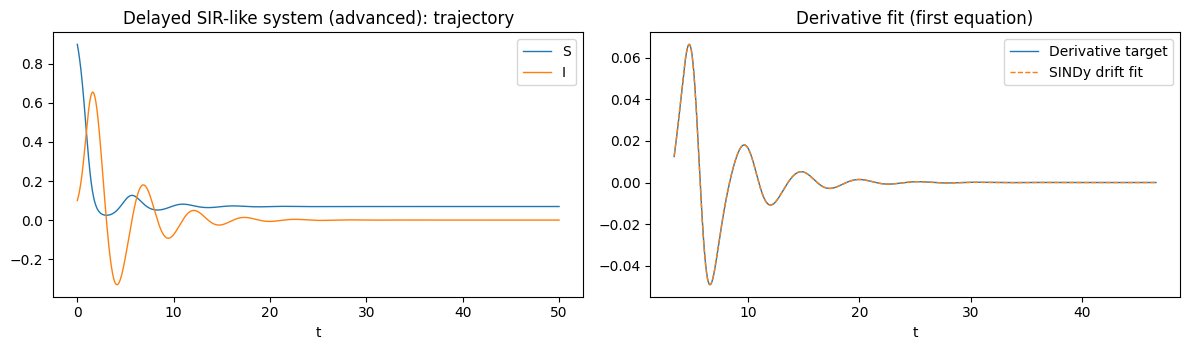

In [16]:
# =============================================================================
# Example 4: two-state delayed SIR-like system (ADVANCED)
# dS/dt = -3*S*I; dI/dt = 3*S*I - I(t-1)
# This is NOT a positivity-preserving epidemiological model.
# Some spurious polynomial terms may be selected due to collinearity.
# =============================================================================
dt_sir, true_sir, beta, mu = 0.02, 1.0, 3.0, 1.0

def rhs_sir(x, z):
    S, I = x
    return np.array([-beta*S*I, beta*S*I - mu*z[1]])

t_sir, x_sir = simulate_dde(
    rhs_sir, history=[0.9, 0.1], tau=true_sir, dt=dt_sir,
    total_time=50, sigma=0.0
)
model_sir = FourierDelaySINDy(
    degree=2, poly_on='both',
    delay_bounds=(0.2, 3.0), max_delay=3.0,
    cutoff_period=0.15, sg_window=31,
    threshold=0.22, n_starts=8, n_alternations=2,
    adam_lr=0.05, adam_iters=250, random_state=48,
    selection='bic'
)
model_sir.fit(x_sir, t=dt_sir, feature_names=['S','I'])
report_model('Delayed SIR-like system (advanced)', true_sir,
             t_sir, x_sir, model_sir, ['S','I'])
results.append(('Delayed SIR-like', true_sir,
                model_sir.delay_, model_sir.mse_))